In [1]:
import joblib # for saving the model
import sys # for checking what environment user is working in
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# model selections
from sklearn.model_selection import train_test_split, cross_val_score
from imblearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

In [2]:
from pathlib import Path
DATA_PATH = Path.home() / 'Downloads' / 'cleaned_data_v2/aug_data_v2'

print("Dataset path:", DATA_PATH)
print("Dataset folder exists:", DATA_PATH.exists())

Dataset path: /home/enby/Downloads/cleaned_data_v2/aug_data_v2
Dataset folder exists: True


In [3]:
import os
import cv2
import pandas as pd


rows = []

for class_name in os.listdir(DATA_PATH):

    class_path = os.path.join(DATA_PATH, class_name)

    if not os.path.isdir(class_path):
        continue

    for file_name in os.listdir(class_path):

        file_path = os.path.join(class_path, file_name)

        img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)

        if img is None:
            continue

        rows.append({
            "image": img,
            "class_name": class_name,
            "file_name": file_name,
            "path": file_path
        })

df = pd.DataFrame(rows)

print(df.head())

                                               image class_name  \
0  [[0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0,...      angry   
1  [[6, 9, 16, 20, 25, 33, 38, 45, 55, 60, 70, 72...      angry   
2  [[60, 84, 96, 117, 128, 142, 155, 156, 162, 16...      angry   
3  [[139, 116, 118, 129, 139, 150, 149, 151, 149,...      angry   
4  [[192, 190, 192, 195, 180, 150, 178, 184, 190,...      angry   

             file_name                                               path  
0  augmented_00238.jpg  /home/enby/Downloads/cleaned_data_v2/aug_data_...  
1   original_02019.jpg  /home/enby/Downloads/cleaned_data_v2/aug_data_...  
2   original_01378.jpg  /home/enby/Downloads/cleaned_data_v2/aug_data_...  
3   original_00800.jpg  /home/enby/Downloads/cleaned_data_v2/aug_data_...  
4   original_00914.jpg  /home/enby/Downloads/cleaned_data_v2/aug_data_...  


In [4]:
df.columns

Index(['image', 'class_name', 'file_name', 'path'], dtype='object')

In [5]:
# Define X,y data
X = df['path']
y = df["class_name"].str.lower()

In [6]:
# Train/Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y
                                                    )
split_data = dict(
                zip(
                    ['X_train', 'X_test', 'y_train', 'y_test'],
                    (X_train, X_test, y_train, y_test)
                )
            )
# print the distribution of splitted data to check if it worked correctly
for label, array in split_data.items():
    print(f"{label}: {array.shape}")

X_train: (8400,)
X_test: (2100,)
y_train: (8400,)
y_test: (2100,)


In [7]:
# This is where the Eigenface augmentation gets done.
### Eigernfaces is basically PCA for image data
### We define the function here:

In [8]:
class Eigenfaces:
    def __init__(self,
                 X_train, X_test, y_train, y_test,
                 img_size):
        self.X_train, self.X_test, self.y_train, self.y_test = X_train, X_test, y_train, y_test
        
        self.img_size=img_size
        
        self.VECTOR_SIZE = self.img_size * self.img_size # size of the eigenface we want to create

        self.mean_face = None
        self.eigenfaces = None


    def data_matrix_creation(self, data):
        # tries to create resized images in preparation for the principle component analysis
        data_matrix = np.zeros(
            (len(data), self.VECTOR_SIZE)
        )
        for idx, path in enumerate(data):
            img = cv2.imread(
                path,
                cv2.IMREAD_GRAYSCALE
            )
            if img is None:
                continue
            resized = cv2.resize(
                img,
                (self.img_size, self.img_size)
            )
            
            resized = resized.astype(np.float32) / 255.0
            
            data_matrix[idx] = resized.flatten()
            
        return data_matrix
            
    def PCA(self, n_components=100): # x=X_train, y=y_train
        data_matrix = self.data_matrix_creation(
            self.X_train
        )

        # calculate the avg face
        self.mean_face = np.mean(
            data_matrix,
            axis=0
        )
    
        # mean-center of the dataset
        centered = (
            data_matrix - self.mean_face
        )
    
        # computing the PCA using SVD
        print("Computing SVD to create the basis space...")
        U, self.S, Vt = np.linalg.svd(
            centered,
            full_matrices=False
        )
    
        # Save top k faces
        self.eigenfaces = Vt[:n_components]
    
        # Projections
        X_train_proj = (
            centered @ self.eigenfaces.T
        )

        self.pca_df = pd.DataFrame(
            X_train_proj[:, :2],
            columns=["PC1", "PC2"]
        )
        self.pca_df["Emotion"] = self.y_train.values
        print("Done!")
        
        return X_train_proj


    def Transform(self):
        data_matrix = self.data_matrix_creation(
            self.X_test
        )
    
        centered = (
            data_matrix - self.mean_face
        )
    
        X_test_proj = (
            centered @ self.eigenfaces.T
        )
    
        return X_test_proj

    def PlotEigenfaces(self, n_faces=6, 
                       array=False, scatter=False, scree=False
                      ):
        if array is True:
            if self.eigenfaces is None:
                raise ValueError(
                    "Run PCA() before plotting eigenfaces."
                )
        
            fig, axes = plt.subplots(
                2,
                (n_faces + 1) // 2,
                figsize=(12, 6)
            )
        
            axes = np.array(axes).flatten()
        
            for i in range(min(n_faces, len(self.eigenfaces))):
                eigenface = self.eigenfaces[i].reshape(
                    self.img_size,
                    self.img_size
                )
        
                eigenface = cv2.normalize(
                    eigenface,
                    None,
                    0,
                    255,
                    cv2.NORM_MINMAX
                )
        
                axes[i].imshow(
                    eigenface,
                    cmap="gray"
                )
        
                axes[i].set_title(
                    f"Eigenface {i+1}"
                )
        
                axes[i].axis("off")
            plt.suptitle(f"Top {n_faces} Facial Variance")
            plt.tight_layout()
        
            plt.show()
            
        if scatter is True:
            sns.scatterplot(
                data=self.pca_df,
                x="PC1", y="PC2",
                hue="Emotion"
            )

        if scree is True:
            exp_var = (
                self.S**2 /
                np.sum(self.S**2)
            )
        
            cum_var = np.cumsum(exp_var)
        
            num_components = len(exp_var)

            optimal_k = np.argmax(cum_var >= .9) + 1
        
            fig, ax1 = plt.subplots(
                figsize=(12, 6)
            )
        
            ax1.bar(
                range(1, num_components + 1),
                exp_var,
                alpha=0.6,
                color="steelblue",
                label="Individual Variance"
            )
        
            ax1.set_xlabel(
                "Principal Component"
            )
        
            ax1.set_ylabel(
                "Explained Variance Ratio",
                color="steelblue"
            )
        
            ax1.tick_params(
                axis="y",
                labelcolor="steelblue"
            )
        
            ax2 = ax1.twinx()
        
            ax2.plot(
                range(1, num_components + 1),
                cum_var,
                color="darkorange",
                marker="o",
                linewidth=2,
                label="Cumulative Variance"
            )
        
            ax2.set_ylabel(
                "Cumulative Variance",
                color="darkorange"
            )
        
            ax2.tick_params(
                axis="y",
                labelcolor="darkorange"
            )

            # Horizontal Threshold
            ax2.axhline(
                y=0.90,
                color="red",
                linestyle="--",
                alpha=0.7,
                label="90% Threshold"
            )
            
            # Vertical Threshold
            ax2.axvline(
                x=optimal_k,
                color="red",
                linestyle=":",
                linewidth=2,
                label=f"{optimal_k -1}"
            )

            # single point
            ax2.scatter(
                optimal_k,
                cum_var[optimal_k - 1],
                color='green',
                s=100,
                zorder=5
            )
            ax2.annotate(
                f'k={optimal_k}\n{cum_var[optimal_k-1]:.1%}',
                xy=(optimal_k,
                    cum_var[optimal_k-1]),
                xytext=(optimal_k+5,
                        cum_var[optimal_k-1]-0.1),
                arrowprops=dict(
                    arrowstyle='->',
                    color='green'
                )
            )
            lines1, labels1 = ax1.get_legend_handles_labels()
        
            lines2, labels2 = ax2.get_legend_handles_labels()
        
            ax1.legend(
                lines1 + lines2,
                labels1 + labels2,
                loc="center right"
            )
        
            plt.title(
                "Eigenfaces Scree Plot"
            )
        
            plt.tight_layout()
        
            plt.show()

### Note, for image size, start with `img_size=48` and increase by factorization (eg. +1, +2, +3, +4, +6, +12, +16, +24, +48) 
#### Why? This takes a lot of CPU power (opimization problem)

In [25]:
Eigen = Eigenfaces(
    X_train, X_test,
    y_train, y_test,
    img_size=60
)

X_train_proj = Eigen.PCA(
    n_components=100
)
X_test_proj = Eigen.Transform()

Computing SVD to create the basis space...
Done!


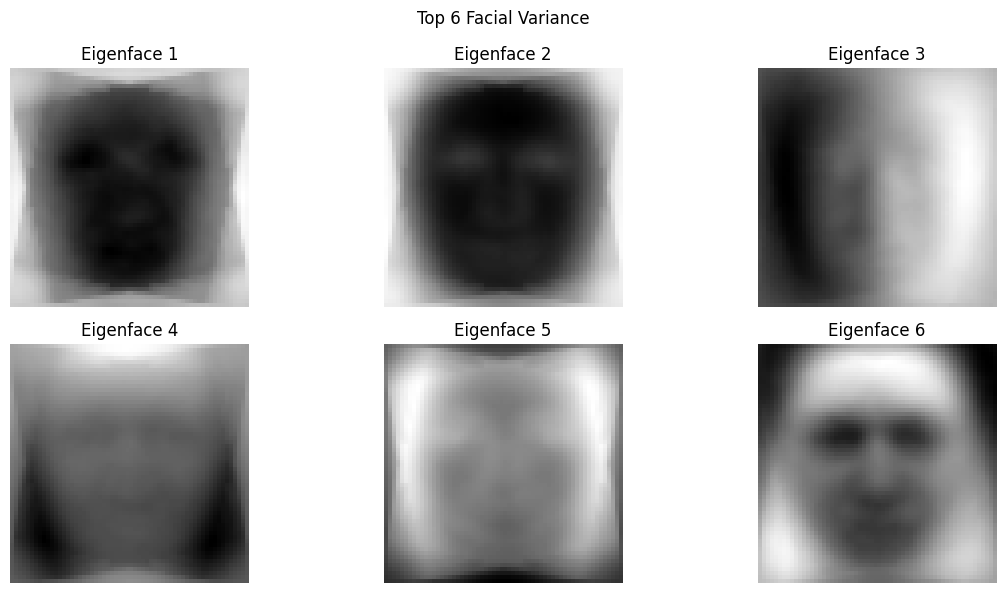

In [26]:
Eigen.PlotEigenfaces(n_faces=6, array=True)

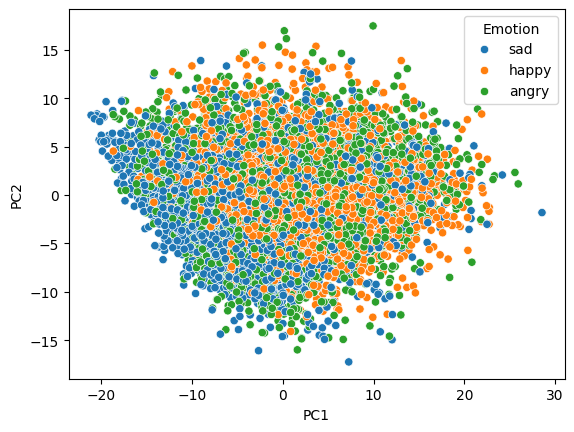

In [27]:
Eigen.PlotEigenfaces(n_faces=6, scatter=True)

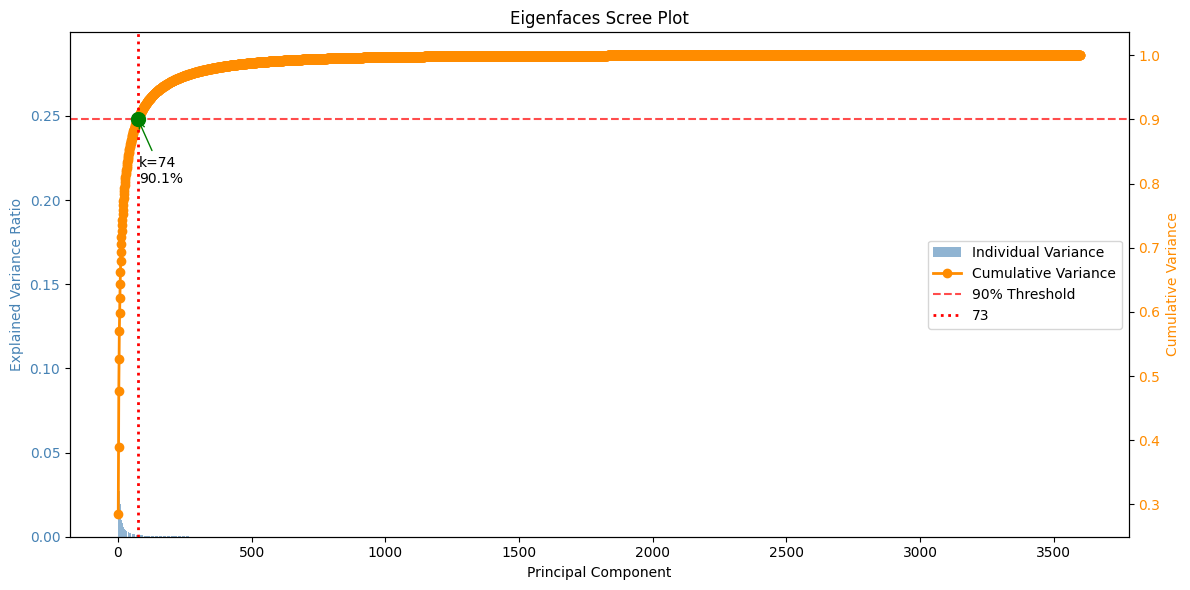

In [28]:
Eigen.PlotEigenfaces(n_faces=6, scree=True)

### optimal k shows `74` so we run the PCA again with k being a fixed number for `n_components`

In [29]:
Eigen = Eigenfaces(
    X_train, X_test,
    y_train, y_test,
    img_size=60
)

X_train_proj = Eigen.PCA(
    n_components=74
)
X_test_proj = Eigen.Transform()

Computing SVD to create the basis space...
Done!


In [30]:
# Define the pipeline here, fit the data, print a classification report
from sklearn.ensemble import RandomForestClassifier
pipe = Pipeline([
    ('classifier', RandomForestClassifier(max_depth=None, n_estimators=100, random_state=42,n_jobs=-1))
])
pipe.fit(
    X_train_proj,
    y_train
)
y_pred = pipe.predict(
    X_test_proj
)
print(classification_report(y_test, y_pred, target_names=['Angry', 'Happy', 'Sad']))

              precision    recall  f1-score   support

       Angry       0.60      0.48      0.54       700
       Happy       0.69      0.79      0.74       700
         Sad       0.73      0.76      0.75       700

    accuracy                           0.68      2100
   macro avg       0.67      0.68      0.67      2100
weighted avg       0.67      0.68      0.67      2100



In [31]:
cm = confusion_matrix(y_test, y_pred)

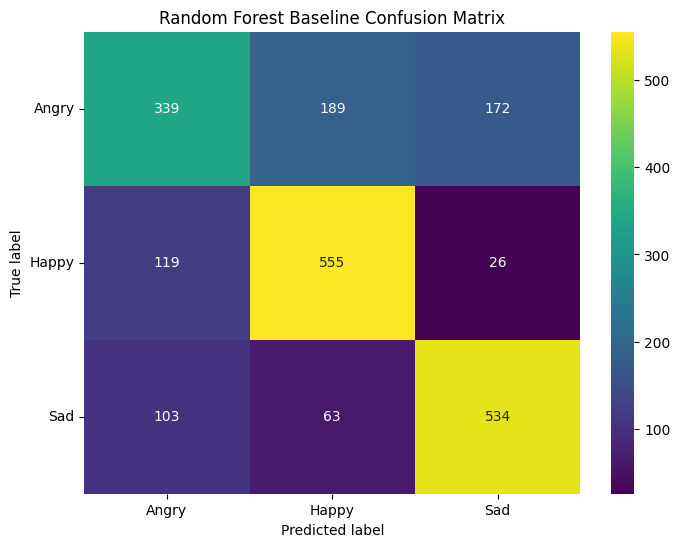

In [32]:
# use seaborn and matplotlib to plot
import seaborn as sns
import matplotlib.pyplot as plt

class_names = ['Angry', 'Happy', 'Sad']

plt.figure(figsize=(8,6))

sns.heatmap(
cm,
annot=True,
fmt='d',
cmap='viridis',
xticklabels=class_names,
yticklabels=class_names
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.yticks(rotation=360)
plt.title("Random Forest Baseline Confusion Matrix")
plt.savefig("Conf_Matrix_Eigen_v2.png")
plt.show()

In [33]:
# save the model with joblib
joblib.dump(pipe, 'random_forest_eigen_v2.joblib')

['random_forest_eigen_v2.joblib']

# Version 2 Final Notes:
* ### This version runs the fastest but misclassifies more than version 1; classifies better than version 3
* * ### This could be due to:
  * ### Happy being undersampled and not augmented
  * ### Only Angry + Sad were augmented
  * ### each class count = 3500